In [1]:

from pathlib import Path
import sys
import importlib.metadata as metadata
import numpy as np

ROOT = Path.cwd()
SRC = ROOT / "src"
DATA_FILE = ROOT / "data" / "pbmc3k_hvg_panel.h5ad"
MODEL_FILE = SRC / "vae_torch.py"

print(" ENVIRONMENT CHECK")
print("-" * 40)
print("Project:", ROOT)
print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("PyTorch package:", metadata.version("torch"))
print("Dataset exists:", DATA_FILE.exists())
print("VAE file exists:", MODEL_FILE.exists())

if MODEL_FILE.exists():
    print("VAE file size:", MODEL_FILE.stat().st_size, "bytes")
    print("Contains VAE class:", "class VAE" in MODEL_FILE.read_text())

 ENVIRONMENT CHECK
----------------------------------------
Project: /Users/gorgeous_jane/pbmc3k-vae-explainability
Python: /Users/gorgeous_jane/.venv/bin/python
NumPy: 1.26.4
PyTorch package: 2.2.2
Dataset exists: True
VAE file exists: True
VAE file size: 1805 bytes
Contains VAE class: True


In [2]:
import sys
import importlib.metadata as metadata

print("Python:", sys.executable)

for package in ["numpy", "pandas", "scanpy", "torch"]:
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        print(package, "Not installed")

Python: /Users/gorgeous_jane/.venv/bin/python
numpy 1.26.4
pandas 2.2.3
scanpy 1.11.5
torch 2.2.2


In [3]:
import sys
import torch
import importlib

# Import the existing model file
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import vae_torch
importlib.reload(vae_torch)

from vae_torch import VAE, set_seed, vae_loss

# Reproducibility
set_seed(42)

# Initialise model
model = VAE(n_genes=2006, latent_dim=16)

# Test with a small artificial batch
test_input = torch.rand(4, 2006)

reconstructed, mu, logvar = model(test_input)

loss, reconstruction_loss, kl_loss = vae_loss(
    reconstructed, test_input, mu, logvar
)

# Test gradient calculation
loss.backward()

print("PYTORCH VAE TEST")
print("-" * 40)
print("Model imported successfully")
print("Input shape:", test_input.shape)
print("Reconstruction shape:", reconstructed.shape)
print("Latent mean shape:", mu.shape)
print("Latent variance shape:", logvar.shape)
print("Total loss:", loss.item())
print("Reconstruction loss:", reconstruction_loss.item())
print("KL loss:", kl_loss.item())
print("Gradient calculation:", "Successful" if model.fc_mu.weight.grad is not None else "Failed")
print("All outputs finite:", bool(torch.isfinite(reconstructed).all()))


PYTORCH VAE TEST
----------------------------------------
Model imported successfully
Input shape: torch.Size([4, 2006])
Reconstruction shape: torch.Size([4, 2006])
Latent mean shape: torch.Size([4, 16])
Latent variance shape: torch.Size([4, 16])
Total loss: 689.2645263671875
Reconstruction loss: 689.1240234375
KL loss: 0.1404796987771988
Gradient calculation: Successful
All outputs finite: True


In [4]:
import sys
import anndata
import scanpy
import h5py

print("NOTEBOOK ENVIRONMENT")
print("-" * 40)
print("Python:", sys.executable)
print("AnnData:", anndata.__version__)
print("Scanpy:", scanpy.__version__)
print("h5py:", h5py.__version__)

print("\nHDF5 METADATA")
with h5py.File(DATA_FILE, "r") as f:
    print("uns keys:", list(f["uns"].keys()))
    print("log1p keys:", list(f["uns/log1p"].keys()))
    print("base attributes:", dict(f["uns/log1p/base"].attrs))

NOTEBOOK ENVIRONMENT
----------------------------------------
Python: /Users/gorgeous_jane/.venv/bin/python
AnnData: 0.11.4
Scanpy: 1.11.5
h5py: 3.16.0

HDF5 METADATA
uns keys: ['hvg', 'log1p']
log1p keys: ['base']
base attributes: {'encoding-type': 'null', 'encoding-version': '0.1.0'}


/var/folders/_d/g3_c0q8j10ngrt_d18t66p580000gn/T/ipykernel_83603/2625215600.py:10: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", scanpy.__version__)


In [5]:
BACKUP_FILE = DATA_FILE.with_name(
    "pbmc3k_hvg_panel_original_backup.h5ad"
)

import shutil

if not BACKUP_FILE.exists():
    shutil.copy2(DATA_FILE, BACKUP_FILE)

print("Original dataset preserved:", BACKUP_FILE.exists())
print("Original file size:", DATA_FILE.stat().st_size)
print("Backup file size:", BACKUP_FILE.stat().st_size)

Original dataset preserved: True
Original file size: 4397880
Backup file size: 4397880


In [6]:
import shutil
import h5py

REPAIRED_FILE = DATA_FILE.with_name(
    "pbmc3k_hvg_panel_repaired.h5ad"
)


print("Repaired copy created:", REPAIRED_FILE.exists())
print("Original preserved:", DATA_FILE.exists())
print("Backup preserved:", BACKUP_FILE.exists())

Repaired copy created: True
Original preserved: True
Backup preserved: True


In [11]:
import scanpy as sc
import numpy as np
import pandas as pd
from pathlib import Path

print("Scanpy version:", sc.__version__)
print("Imports restored successfully.")

Scanpy version: 1.11.5
Imports restored successfully.


/var/folders/_d/g3_c0q8j10ngrt_d18t66p580000gn/T/ipykernel_83603/2787346788.py:6: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy version:", sc.__version__)


In [12]:
adata = sc.read_h5ad(REPAIRED_FILE)

print("PBMC DATASET LOADED SUCCESSFULLY")
print("-" * 45)
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Expression matrix:", type(adata.X))
print("Cell annotations:", adata.obs.columns.tolist())
print("\nTrain/test split:")
print(adata.obs["split"].value_counts())
print("\nCell-type distribution:")
print(adata.obs["louvain_cluster"].value_counts())

PBMC DATASET LOADED SUCCESSFULLY
---------------------------------------------
Cells: 2638
Genes: 2006
Expression matrix: <class 'scipy.sparse._csr.csr_matrix'>
Cell annotations: ['n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'louvain_cluster', 'split']

Train/test split:
split
train    2110
test      528
Name: count, dtype: int64

Cell-type distribution:
louvain_cluster
CD4 T cells          1144
CD14+ Monocytes       480
B cells               342
CD8 T cells           316
NK cells              154
FCGR3A+ Monocytes     150
Dendritic cells        37
Megakaryocytes         15
Name: count, dtype: int64


In [13]:
from scipy import sparse
import numpy as np

print("EXPRESSION MATRIX VALIDATION")
print("-" * 45)

X = adata.X

print("Matrix shape:", X.shape)
print("Sparse matrix:", sparse.issparse(X))
print("Data type:", X.dtype)

if sparse.issparse(X):
    values = X.data
else:
    values = X.ravel()

print("NaN values:", np.isnan(values).sum())
print("Infinite values:", np.isinf(values).sum())
print("Minimum expression:", values.min())
print("Maximum expression:", values.max())

print("Unique gene names:", adata.var_names.is_unique)
print("Unique cell IDs:", adata.obs_names.is_unique)

print("\nValidation complete.")

EXPRESSION MATRIX VALIDATION
---------------------------------------------
Matrix shape: (2638, 2006)
Sparse matrix: True
Data type: float32
NaN values: 0
Infinite values: 0
Minimum expression: 0.7546
Maximum expression: 7.4695992
Unique gene names: True
Unique cell IDs: True

Validation complete.


In [14]:
import torch
from torch.utils.data import TensorDataset, DataLoader, Subset

SEED = 42
BATCH_SIZE = 128

# Reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)

# Convert sparse matrix to one dense float32 array
X_dense = adata.X.toarray().astype(np.float32, copy=False)

# Create PyTorch dataset
X_tensor = torch.from_numpy(X_dense)
dataset = TensorDataset(X_tensor)

# Use the existing split
train_indices = np.where(
    adata.obs["split"].values == "train"
)[0]

test_indices = np.where(
    adata.obs["split"].values == "test"
)[0]

train_dataset = Subset(dataset, train_indices.tolist())
test_dataset = Subset(dataset, test_indices.tolist())

# Data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("PYTORCH DATA PREPARATION")
print("-" * 45)
print("Full tensor:", X_tensor.shape)
print("Tensor dtype:", X_tensor.dtype)
print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)

PYTORCH DATA PREPARATION
---------------------------------------------
Full tensor: torch.Size([2638, 2006])
Tensor dtype: torch.float32
Training samples: 2110
Test samples: 528
Training batches: 17
Test batches: 5
Batch size: 128


In [15]:
from src.vae_torch import VAE, set_seed, vae_loss

# Reproducibility
set_seed(SEED)

# Model configuration
N_GENES = adata.n_vars
LATENT_DIM = 16
HIDDEN_DIMS = (256, 64)
LEARNING_RATE = 1e-3

# Use CPU initially
device = torch.device("cpu")

# Initialise VAE
model = VAE(
    n_genes=N_GENES,
    latent_dim=LATENT_DIM,
    hidden=HIDDEN_DIMS
).to(device)

# Optimiser
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Count trainable parameters
total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("VAE MODEL CONFIGURATION")
print("-" * 45)
print("Input genes:", N_GENES)
print("Latent dimensions:", LATENT_DIM)
print("Hidden dimensions:", HIDDEN_DIMS)
print("Learning rate:", LEARNING_RATE)
print("Device:", device)
print("Trainable parameters:", f"{total_parameters:,}")
print("Model initialised:", isinstance(model, VAE))
print("Optimiser:", type(optimizer).__name__)

VAE MODEL CONFIGURATION
---------------------------------------------
Input genes: 2006
Latent dimensions: 16
Hidden dimensions: (256, 64)
Learning rate: 0.001
Device: cpu
Trainable parameters: 1,065,590
Model initialised: True
Optimiser: Adam


In [16]:
import time

EPOCHS = 100
KL_WARMUP_EPOCHS = 20

history = {
    "total_loss": [],
    "reconstruction_loss": [],
    "kl_loss": [],
    "beta": []
}

print("STARTING VAE TRAINING")
print("-" * 55)

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    model.train()

    # Gradually increase KL weight from 0 to 1
    beta = min(1.0, epoch / KL_WARMUP_EPOCHS)

    epoch_total = 0.0
    epoch_recon = 0.0
    epoch_kl = 0.0
    n_samples = 0

    for (batch,) in train_loader:

        batch = batch.to(device)

        optimizer.zero_grad()

        reconstruction, mu, logvar = model(batch)

        loss, recon_loss, kl_loss = vae_loss(
            reconstruction,
            batch,
            mu,
            logvar,
            beta=beta
        )

        loss.backward()
        optimizer.step()

        batch_size = batch.size(0)

        epoch_total += loss.item() * batch_size
        epoch_recon += recon_loss.item() * batch_size
        epoch_kl += kl_loss.item() * batch_size
        n_samples += batch_size

    # Average losses across all training cells
    avg_total = epoch_total / n_samples
    avg_recon = epoch_recon / n_samples
    avg_kl = epoch_kl / n_samples

    history["total_loss"].append(avg_total)
    history["reconstruction_loss"].append(avg_recon)
    history["kl_loss"].append(avg_kl)
    history["beta"].append(beta)

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d}/{EPOCHS} | "
            f"Beta: {beta:.2f} | "
            f"Total: {avg_total:.4f} | "
            f"Recon: {avg_recon:.4f} | "
            f"KL: {avg_kl:.4f}"
        )

elapsed = time.time() - start_time

print("-" * 55)
print("TRAINING COMPLETED")
print(f"Time taken: {elapsed / 60:.2f} minutes")
print("Final reconstruction loss:", history["reconstruction_loss"][-1])
print("Final KL loss:", history["kl_loss"][-1])

STARTING VAE TRAINING
-------------------------------------------------------
Epoch 001/100 | Beta: 0.05 | Total: 766.2188 | Recon: 764.9734 | KL: 24.9078
Epoch 010/100 | Beta: 0.50 | Total: 416.2281 | Recon: 407.0255 | KL: 18.4053
Epoch 020/100 | Beta: 1.00 | Total: 408.5531 | Recon: 397.5987 | KL: 10.9544
Epoch 030/100 | Beta: 1.00 | Total: 401.6623 | Recon: 392.6633 | KL: 8.9990
Epoch 040/100 | Beta: 1.00 | Total: 397.8930 | Recon: 389.5031 | KL: 8.3899
Epoch 050/100 | Beta: 1.00 | Total: 394.9282 | Recon: 386.6094 | KL: 8.3187
Epoch 060/100 | Beta: 1.00 | Total: 392.2127 | Recon: 384.0680 | KL: 8.1447
Epoch 070/100 | Beta: 1.00 | Total: 390.0234 | Recon: 381.4417 | KL: 8.5817
Epoch 080/100 | Beta: 1.00 | Total: 387.7224 | Recon: 379.0823 | KL: 8.6401
Epoch 090/100 | Beta: 1.00 | Total: 386.0165 | Recon: 377.1335 | KL: 8.8830
Epoch 100/100 | Beta: 1.00 | Total: 384.2867 | Recon: 375.1252 | KL: 9.1616
-------------------------------------------------------
TRAINING COMPLETED
Time tak

In [17]:
model.eval()

test_total = 0.0
test_recon = 0.0
test_kl = 0.0
test_samples = 0

with torch.no_grad():

    for (batch,) in test_loader:

        batch = batch.to(device)

        reconstruction, mu, logvar = model(batch)

        loss, recon_loss, kl_loss = vae_loss(
            reconstruction,
            batch,
            mu,
            logvar,
            beta=1.0
        )

        n = batch.size(0)

        test_total += loss.item() * n
        test_recon += recon_loss.item() * n
        test_kl += kl_loss.item() * n
        test_samples += n

test_total /= test_samples
test_recon /= test_samples
test_kl /= test_samples

print("HELD-OUT TEST SET EVALUATION")
print("-" * 45)
print("Test cells:", test_samples)
print(f"Total loss: {test_total:.4f}")
print(f"Reconstruction loss: {test_recon:.4f}")
print(f"KL divergence: {test_kl:.4f}")
print(f"Mean squared error per gene: {test_recon / N_GENES:.6f}")

print("\nTRAIN VS TEST")
print("-" * 45)
print(f"Training reconstruction: {history['reconstruction_loss'][-1]:.4f}")
print(f"Test reconstruction: {test_recon:.4f}")
print(f"Training KL: {history['kl_loss'][-1]:.4f}")
print(f"Test KL: {test_kl:.4f}")

HELD-OUT TEST SET EVALUATION
---------------------------------------------
Test cells: 528
Total loss: 398.0298
Reconstruction loss: 389.9554
KL divergence: 8.0743
Mean squared error per gene: 0.194395

TRAIN VS TEST
---------------------------------------------
Training reconstruction: 375.1252
Test reconstruction: 389.9554
Training KL: 9.1616
Test KL: 8.0743


In [18]:
model.eval()

all_mu = []
all_logvar = []

with torch.no_grad():
    for start in range(0, len(X_tensor), BATCH_SIZE):

        batch = X_tensor[start:start + BATCH_SIZE].to(device)

        mu, logvar = model.encode(batch)

        all_mu.append(mu.cpu())
        all_logvar.append(logvar.cpu())

# Combine latent representations
latent_mu = torch.cat(all_mu, dim=0)
latent_logvar = torch.cat(all_logvar, dim=0)

# Variance of posterior means across cells
latent_variance = latent_mu.var(dim=0, unbiased=False)

# Average KL contribution per latent dimension
kl_per_dimension = 0.5 * (
    latent_mu.pow(2) +
    latent_logvar.exp() -
    1 -
    latent_logvar
).mean(dim=0)

ACTIVE_THRESHOLD = 0.01
active_dimensions = (latent_variance > ACTIVE_THRESHOLD).sum().item()

print("LATENT DIMENSION ACTIVITY")
print("-" * 55)
print("Cells:", latent_mu.shape[0])
print("Latent dimensions:", latent_mu.shape[1])
print("Active dimensions:", active_dimensions)
print("Inactive dimensions:", LATENT_DIM - active_dimensions)
print("\nDimension | Variance | Mean KL | Status")
print("-" * 55)

for i in range(LATENT_DIM):
    variance = latent_variance[i].item()
    kl_value = kl_per_dimension[i].item()
    status = "Active" if variance > ACTIVE_THRESHOLD else "Inactive"

    print(
        f"{i + 1:9d} | {variance:8.4f} | "
        f"{kl_value:7.4f} | {status}"
    )

print("\nLatent representation shape:", tuple(latent_mu.shape))

LATENT DIMENSION ACTIVITY
-------------------------------------------------------
Cells: 2638
Latent dimensions: 16
Active dimensions: 13
Inactive dimensions: 3

Dimension | Variance | Mean KL | Status
-------------------------------------------------------
        1 |   0.0103 |  0.0067 | Active
        2 |   1.1469 |  1.5430 | Active
        3 |   0.0078 |  0.0053 | Inactive
        4 |   0.0245 |  0.0153 | Active
        5 |   1.0354 |  1.3020 | Active
        6 |   0.0129 |  0.0104 | Active
        7 |   1.1795 |  1.7277 | Active
        8 |   0.0132 |  0.0077 | Active
        9 |   0.4367 |  0.5371 | Active
       10 |   0.0036 |  0.0024 | Inactive
       11 |   0.0285 |  0.0151 | Active
       12 |   0.0315 |  0.0177 | Active
       13 |   0.0079 |  0.0052 | Inactive
       14 |   0.9950 |  1.4368 | Active
       15 |   1.2962 |  1.9851 | Active
       16 |   0.3349 |  0.2990 | Active

Latent representation shape: (2638, 16)


In [19]:
# Create output directories
MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs"

MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# Save trained model and configuration
MODEL_FILE = MODEL_DIR / "vae_torch_seed42.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "n_genes": N_GENES,
    "latent_dim": LATENT_DIM,
    "hidden_dims": HIDDEN_DIMS,
    "seed": SEED,
    "epochs": EPOCHS,
    "history": history
}, MODEL_FILE)

# Save posterior latent means and log variances
LATENT_FILE = OUTPUT_DIR / "vae_latent_seed42.npz"

np.savez_compressed(
    LATENT_FILE,
    latent_mu=latent_mu.numpy(),
    latent_logvar=latent_logvar.numpy(),
    cell_ids=adata.obs_names.astype(str).to_numpy(),
    cell_types=adata.obs["louvain_cluster"].astype(str).to_numpy(),
    split=adata.obs["split"].astype(str).to_numpy()
)

print("MODEL AND LATENT DATA SAVED")
print("-" * 45)
print("Model:", MODEL_FILE)
print("Latent data:", LATENT_FILE)
print("Latent matrix:", tuple(latent_mu.shape))
print("Model file exists:", MODEL_FILE.exists())
print("Latent file exists:", LATENT_FILE.exists())

MODEL AND LATENT DATA SAVED
---------------------------------------------
Model: /Users/gorgeous_jane/pbmc3k-vae-explainability/models/vae_torch_seed42.pt
Latent data: /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/vae_latent_seed42.npz
Latent matrix: (2638, 16)
Model file exists: True
Latent file exists: True


In [20]:
# Create an AnnData object from the VAE latent representations

adata_latent = sc.AnnData(
    X=latent_mu.numpy().astype(np.float32),
    obs=adata.obs[["louvain_cluster", "split"]].copy()
)

# Name the 16 latent dimensions
adata_latent.var_names = [
    f"latent_{i}" for i in range(1, 17)
]

# Calculate neighbourhood graph
sc.pp.neighbors(
    adata_latent,
    n_neighbors=15,
    use_rep="X",
    random_state=42
)

# Calculate UMAP
sc.tl.umap(
    adata_latent,
    random_state=42
)

print("VAE LATENT UMAP COMPLETED")
print("-" * 40)
print("Cells:", adata_latent.n_obs)
print("Latent dimensions:", adata_latent.n_vars)
print("UMAP coordinates:", adata_latent.obsm["X_umap"].shape)

VAE LATENT UMAP COMPLETED
----------------------------------------
Cells: 2638
Latent dimensions: 16
UMAP coordinates: (2638, 2)


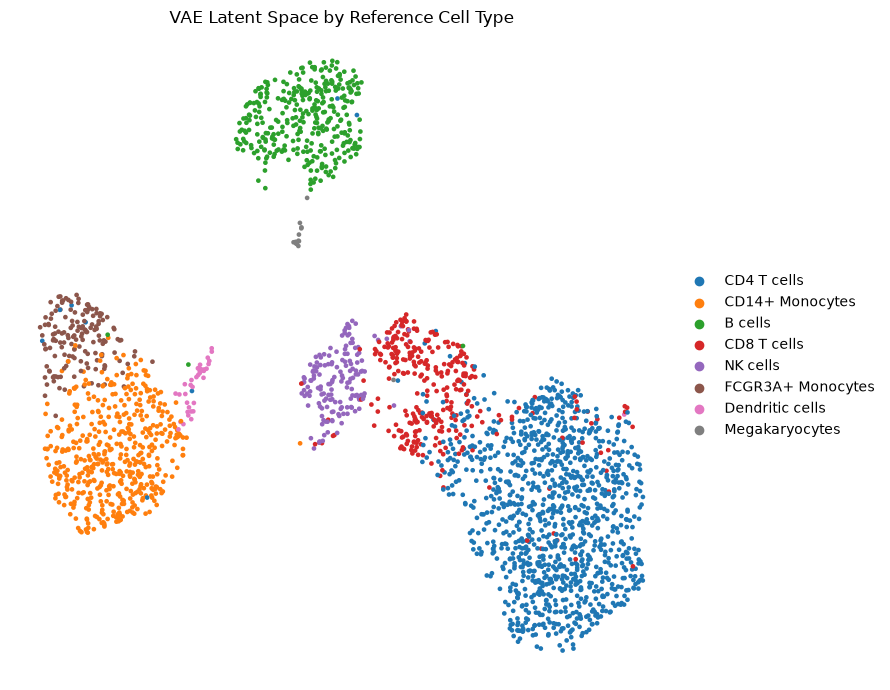

Figure saved: /Users/gorgeous_jane/pbmc3k-vae-explainability/figures/day2_vae_latent_umap.png
File exists: True


In [21]:
# Plot VAE latent space by reference cell type

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))

sc.pl.umap(
    adata_latent,
    color="louvain_cluster",
    frameon=False,
    title="VAE Latent Space by Reference Cell Type",
    legend_loc="right margin",
    ax=ax,
    show=False
)

plt.tight_layout()

# Save figure
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

FIGURE_FILE = FIGURE_DIR / "day2_vae_latent_umap.png"

fig.savefig(
    FIGURE_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", FIGURE_FILE)
print("File exists:", FIGURE_FILE.exists())